Total number of processing samples: 784
Proportion data saved to: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Global_Fragment_analysis/Result/fragment_size_proportions.csv


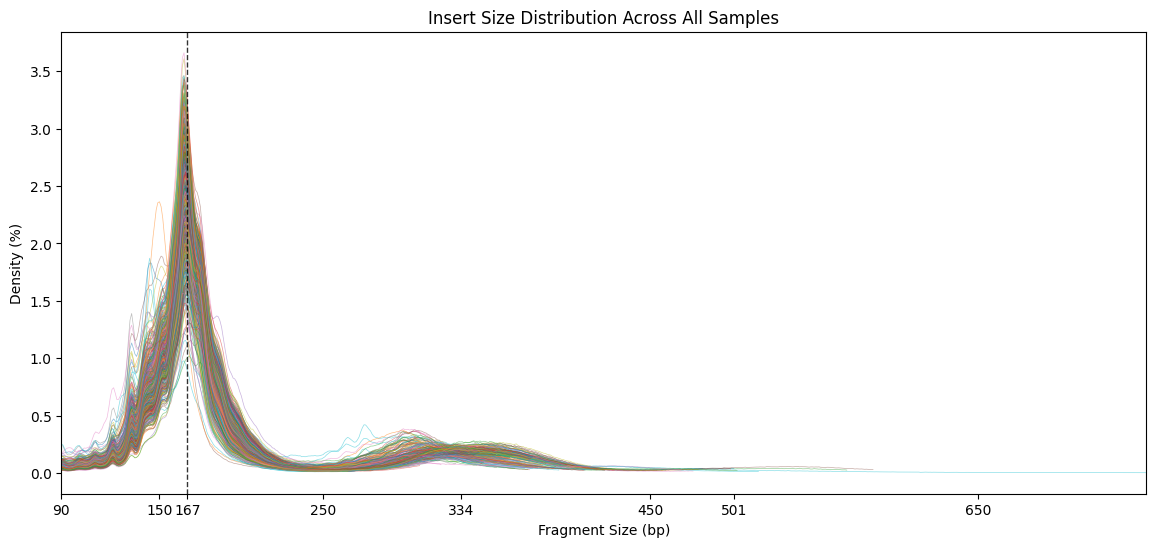

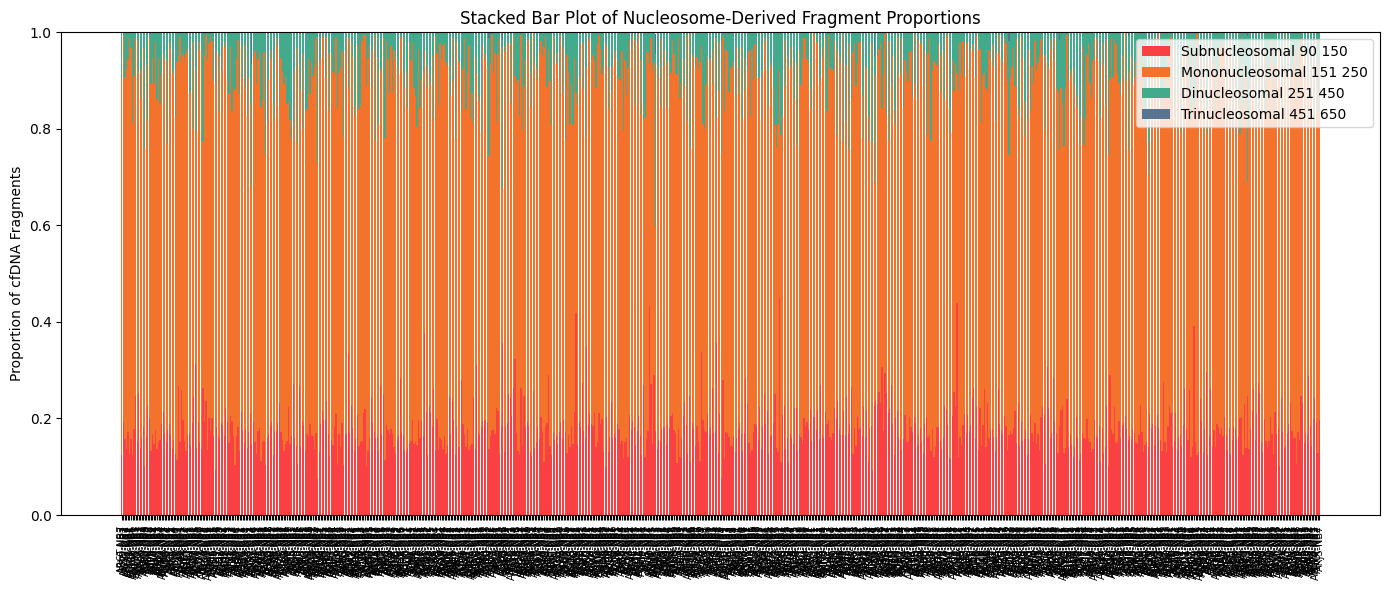

Density and stacked bar plots saved successfully.


In [3]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
import io

# ================================
# CONFIGURATION
# ================================

directory = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Global_Fragment_analysis/Result"
output_directory = directory  # You can modify this if needed

# ================================
# FILE LOADING
# ================================

file_paths = glob.glob(os.path.join(directory, "*.metrics.txt"))
samplenames = [os.path.basename(x).replace(".metrics.txt", "") for x in file_paths]

# Initialize main DataFrame and proportions storage
all_data = pd.DataFrame()
fragment_proportions = {}

# ================================
# PROCESS EACH FILE
# ================================
total_files = len(file_paths)
print(f"Total number of processing samples: {total_files}")

for file_path, sample_name in zip(file_paths, samplenames):
    # print(f"Processing: {file_path}")
    
    with open(file_path, 'r') as file:
        lines = file.readlines()

    histogram_start = next((i for i, line in enumerate(lines) if line.startswith("## HISTOGRAM")), None)
    if histogram_start is None:
        print(f"Warning: No histogram section found in {file_path}")
        continue

    histogram_section = lines[histogram_start + 1:]
    
    try:
        histogram_df = pd.read_csv(io.StringIO("\n".join(histogram_section)), sep="\t", comment='#')
    except pd.errors.EmptyDataError:
        print(f"Warning: No histogram data found in {file_path}")
        continue

    if histogram_df.empty or 'insert_size' not in histogram_df or 'All_Reads.fr_count' not in histogram_df:
        print(f"Warning: Missing required columns in histogram data for {file_path}")
        continue

    histogram_df['insert_size'] = pd.to_numeric(histogram_df['insert_size'], errors='coerce')
    histogram_df['All_Reads.fr_count'] = pd.to_numeric(histogram_df['All_Reads.fr_count'], errors='coerce')
    histogram_df = histogram_df.dropna(subset=['insert_size', 'All_Reads.fr_count'])

    # Filter small fragment sizes
    histogram_df = histogram_df[histogram_df['insert_size'] >= 90]

    # Compute density (%)
    histogram_df['density'] = (histogram_df['All_Reads.fr_count'] / histogram_df['All_Reads.fr_count'].sum()) * 90
    histogram_df['sample'] = sample_name

    # Append to main table
    all_data = pd.concat([all_data, histogram_df], ignore_index=True)

    # ================================
    # PROPORTION CALCULATION (Manuscript-aligned)
    # ================================

    total_counts = histogram_df['All_Reads.fr_count'].sum()
    if total_counts == 0:
        continue

    # Subnucleosomal fragments (ctDNA-enriched)
    sub_nuc = histogram_df[
        (histogram_df['insert_size'] >= 90) &
        (histogram_df['insert_size'] <= 150)
    ]['All_Reads.fr_count'].sum()

    # Mononucleosome (canonical, 151–250 bp)
    mono_nuc = histogram_df[
        (histogram_df['insert_size'] >= 151) &
        (histogram_df['insert_size'] <= 250)
    ]['All_Reads.fr_count'].sum()

    # Dinucleosome (251–450 bp)
    di_nuc = histogram_df[
        (histogram_df['insert_size'] >= 251) &
        (histogram_df['insert_size'] <= 450)
    ]['All_Reads.fr_count'].sum()

    # Trinucleosome (451–650 bp)
    tri_nuc = histogram_df[
        (histogram_df['insert_size'] >= 451) &
        (histogram_df['insert_size'] <= 650)
    ]['All_Reads.fr_count'].sum()

    # Proportions
    prop_sub = sub_nuc / total_counts
    prop_mono = mono_nuc / total_counts
    prop_di = di_nuc / total_counts
    prop_tri = tri_nuc / total_counts

    fragment_proportions[sample_name] = {
        'Subnucleosomal_90_150': prop_sub,
        'Mononucleosomal_151_250': prop_mono,
        'Dinucleosomal_251_450': prop_di,
        'Trinucleosomal_451_650': prop_tri
    }

    # print(f"  ↳ Fragment Proportions for {sample_name}:")
    # print(f"     Subnucleosomal (90–150 bp): {prop_sub:.4f}")
    # print(f"     Mononucleosomal (151–250 bp): {prop_mono:.4f}")
    # print(f"     Dinucleosomal (251–450 bp): {prop_di:.4f}")
    # print(f"     Trinucleosomal (451–650 bp): {prop_tri:.4f}")
    # print()

# ================================
# EXPORT RESULTS
# ================================

# Save fragment proportions
proportion_df = pd.DataFrame.from_dict(fragment_proportions, orient='index').reset_index()
proportion_df.rename(columns={'index': 'Sample'}, inplace=True)
proportion_path = os.path.join(output_directory, "fragment_size_proportions.csv")
proportion_df.to_csv(proportion_path, index=False)
print(f"Proportion data saved to: {proportion_path}")

# ================================
# PLOT 1: Density Plot Across Samples
# ================================

plt.figure(figsize=(14, 6))
for sample in all_data['sample'].unique():
    sample_data = all_data[all_data['sample'] == sample]
    plt.plot(sample_data['insert_size'], sample_data['density'], linewidth=0.5, alpha=0.5)

plt.axvline(167, linewidth=1, color="black", linestyle="--", alpha=0.8)
plt.xlim(90, max(all_data['insert_size']) if not all_data.empty else 700)
plt.xticks([90, 150, 167, 250, 334, 450, 501, 650])
plt.xlabel('Fragment Size (bp)')
plt.ylabel('Density (%)')
plt.title('Insert Size Distribution Across All Samples')
plt.savefig(os.path.join(output_directory, "density_plot_multiple_samples.png"), dpi=300, bbox_inches='tight')
plt.show()

# ================================
# PLOT 2: Stacked Bar Plot of Nucleosome Proportions
# ================================

plt.figure(figsize=(14, 6))

fragment_types = [
    'Subnucleosomal_90_150',
    'Mononucleosomal_151_250',
    'Dinucleosomal_251_450',
    'Trinucleosomal_451_650'
]
colors = ['#f94144', '#f3722c', '#43aa8b', '#577590']

bottom = None
for i, frag in enumerate(fragment_types):
    plt.bar(
        proportion_df['Sample'],
        proportion_df[frag],
        bottom=bottom,
        label=frag.replace('_', ' '),
        color=colors[i]
    )
    bottom = proportion_df[frag] if bottom is None else bottom + proportion_df[frag]

plt.ylabel("Proportion of cfDNA Fragments")
plt.title("Stacked Bar Plot of Nucleosome-Derived Fragment Proportions")
plt.xticks(rotation=90, fontsize=7)
plt.ylim(0, 1)
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.savefig(os.path.join(output_directory, "stacked_nucleosome_proportions.png"), dpi=300, bbox_inches='tight')
plt.show()

print("Density and stacked bar plots saved successfully.")
